## 📖 Background
You work for an international HR consultancy helping companies attract and retain top talent in the competitive tech industry. As part of your services, you provide clients with insights into industry salary trends to ensure they remain competitive in hiring and compensation practices.

Your team wants to use a data-driven approach to analyse how various factors—such as job role, experience level, remote work, and company size—impact salaries globally. By understanding these trends, you can advise clients on offering competitive packages to attract the best talent.

In this competition, you’ll explore and visualise salary data from thousands of employees worldwide. f you're tackling the advanced level, you'll go a step further—building predictive models to uncover key salary drivers and providing insights on how to enhance future data collection.

## 💾 The data

The data comes from a survey hosted by an HR consultancy, available in `'salaries.csv'`.

#### Each row represents a single employee's salary record for a given year:
- **`work_year`** - The year the salary was paid.  
- **`experience_level`** - Employee experience level:  
  - **`EN`**: Entry-level / Junior  
  - **`MI`**: Mid-level / Intermediate  
  - **`SE`**: Senior / Expert  
  - **`EX`**: Executive / Director  
- **`employment_type`** - Employment type:  
  - **`PT`**: Part-time  
  - **`FT`**: Full-time  
  - **`CT`**: Contract  
  - **`FL`**: Freelance  
- **`job_title`** - The job title during the year.  
- **`salary`** - Gross salary paid (in local currency).  
- **`salary_currency`** - Salary currency (ISO 4217 code).  
- **`salary_in_usd`** - Salary converted to USD using average yearly FX rate.  
- **`employee_residence`** - Employee's primary country of residence (ISO 3166 code).  
- **`remote_ratio`** - Percentage of remote work:  
  - **`0`**: No remote work (<20%)  
  - **`50`**: Hybrid (50%)  
  - **`100`**: Fully remote (>80%)  
- **`company_location`** - Employer's main office location (ISO 3166 code).  
- **`company_size`** - Company size:  
  - **`S`**: Small (<50 employees)  
  - **`M`**: Medium (50–250 employees)  
  - **`L`**: Large (>250 employees)  

## 💪 Competition challenge

In this second level, you’ll create visualisations to analyse the data and uncover trends. If you’re up for an even greater challenge, head to level three!
Create a report that answers the following:
- Create a bar chart displaying the top 5 job titles with the highest average salary (in USD).
- Compare the average salaries for employees working remotely 100%, 50%, and 0%. What patterns or trends do you observe?
- Visualise the salary distribution (in USD) across company sizes (S, M, L). Which company size offers the highest average salary?

## 🧑‍⚖️ Judging criteria

This is a community-based competition. Once the competition concludes, you'll have the opportunity to view and vote for the best submissions of others as the voting begins. The top 5 most upvoted entries will win. The winners will receive DataCamp merchandise.

## ✅ Checklist before publishing into the competition
- Rename your workspace to make it descriptive of your work. N.B. you should leave the notebook name as notebook.ipynb.
- **Remove redundant cells** like the judging criteria, so the workbook is focused on your story.
- Make sure the workbook reads well and explains how you found your insights. 
- Try to include an **executive summary** of your recommendations at the beginning.
- Check that all the cells run without error

## ⌛️ Time is ticking. Good luck!

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')


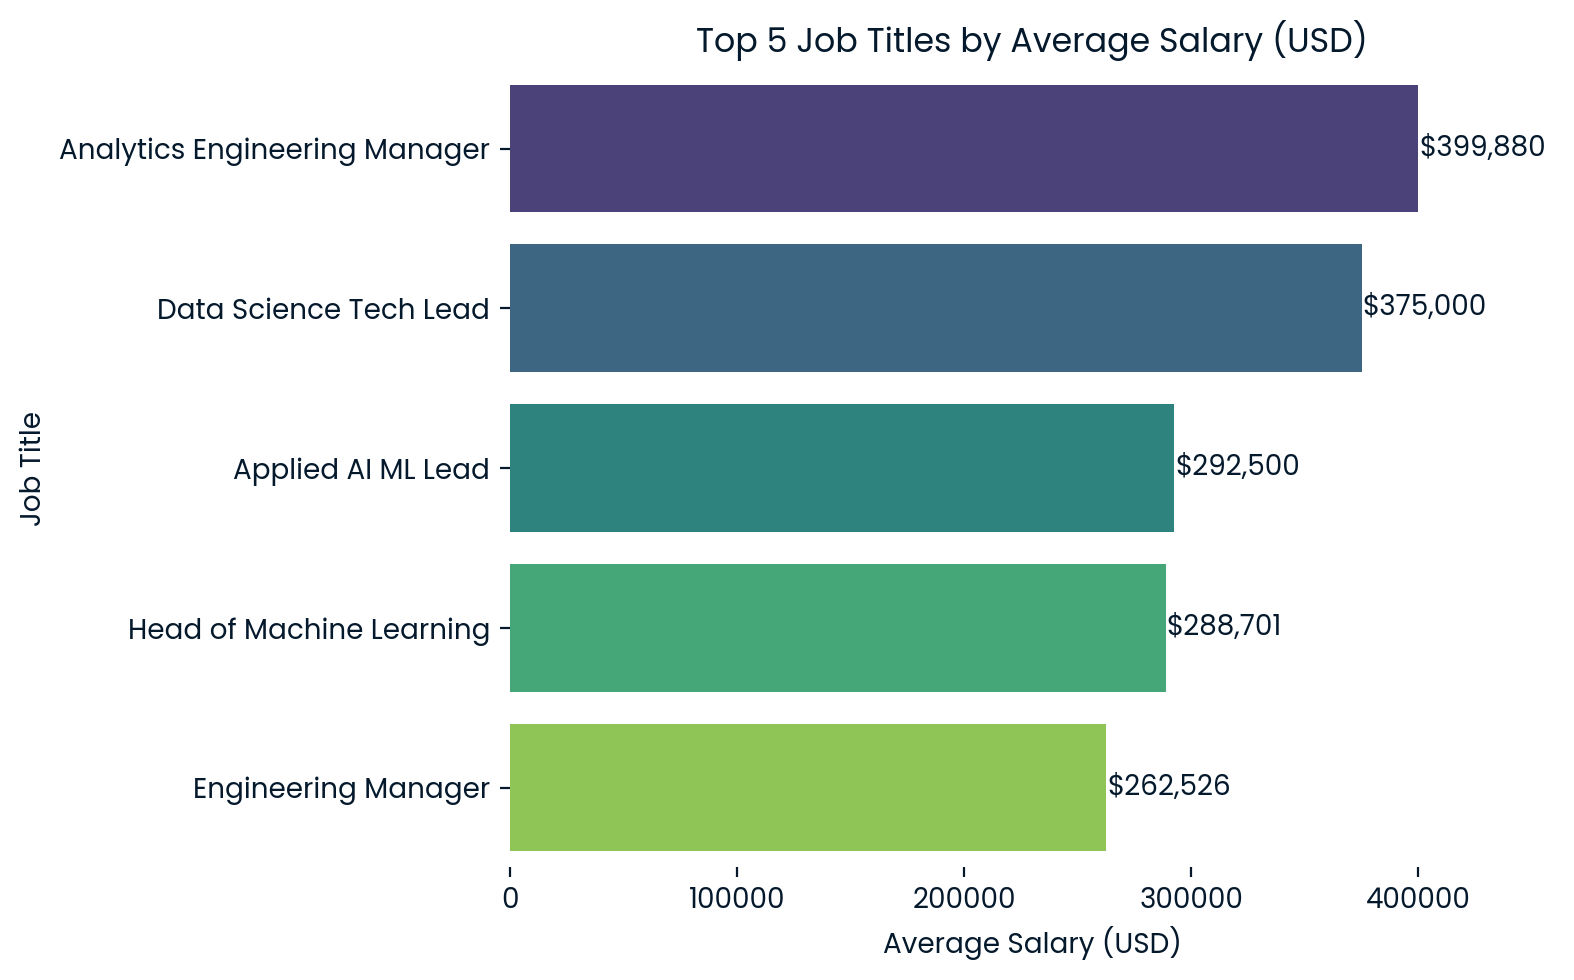

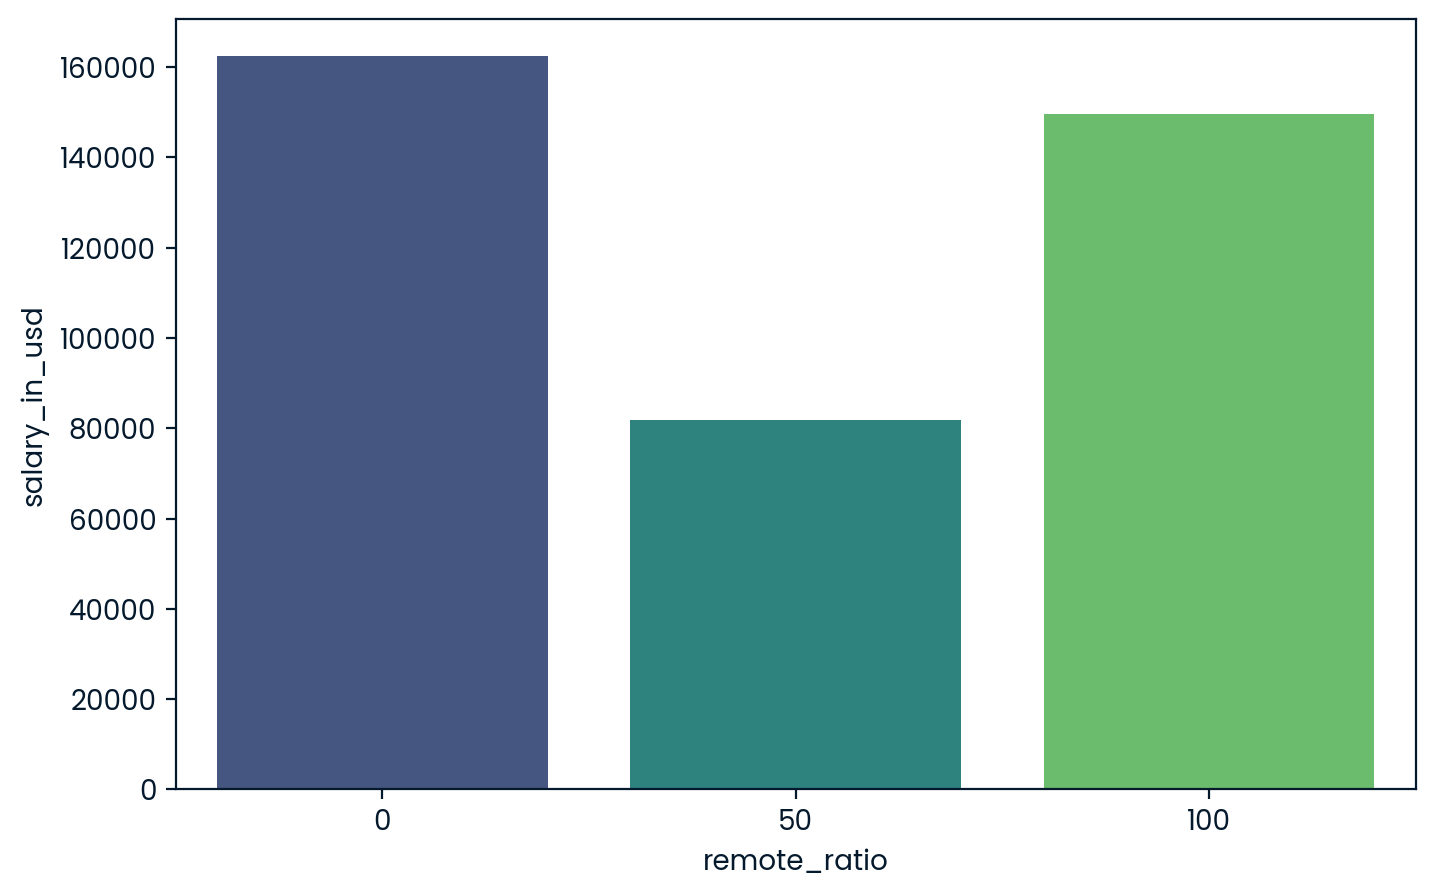

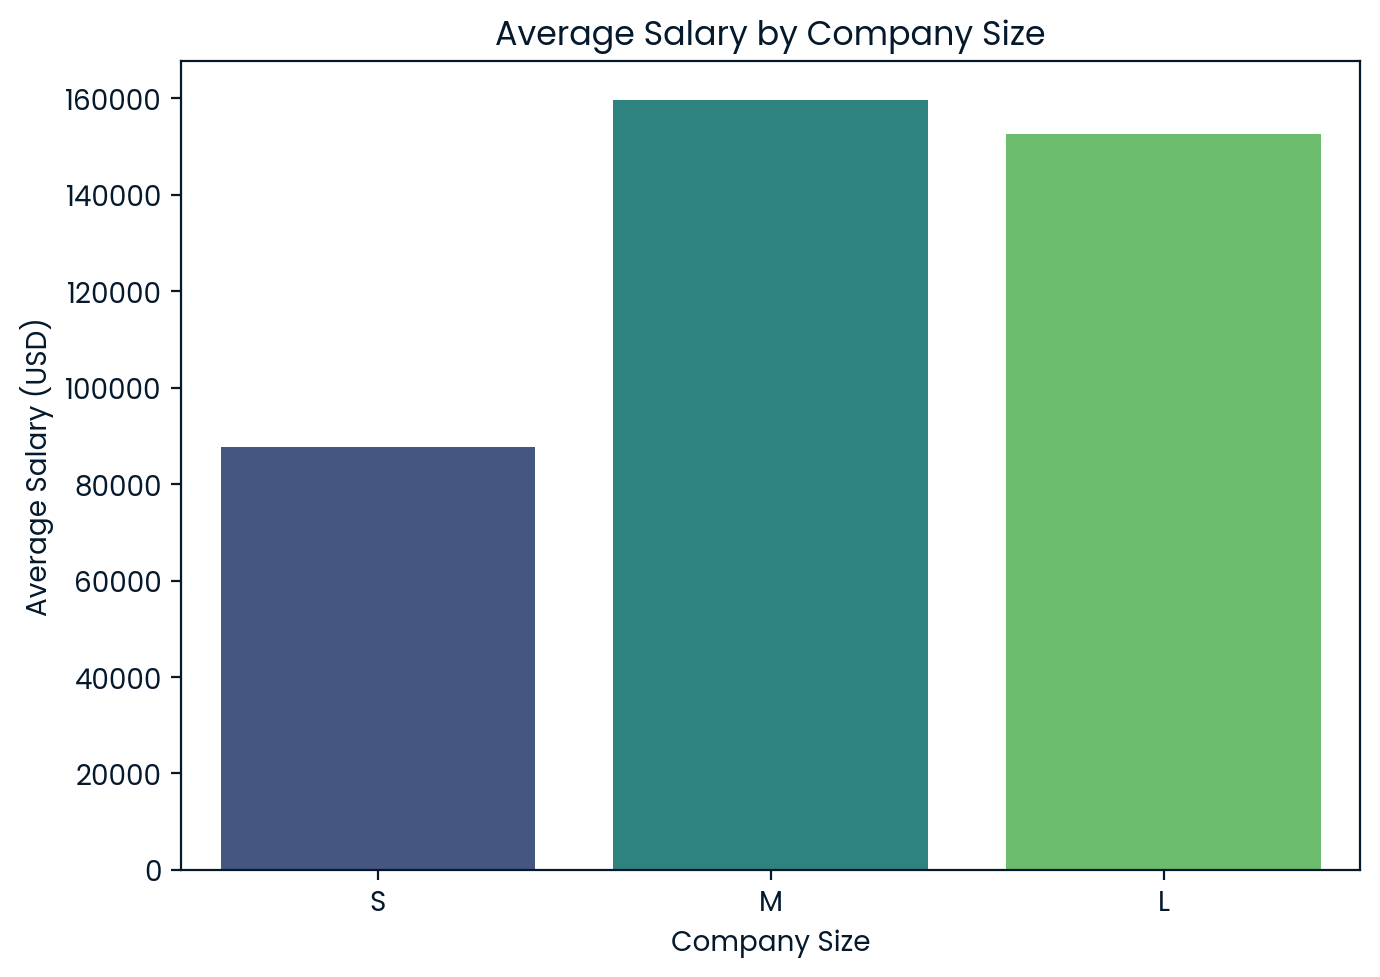

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
salaries = pd.read_csv("salaries.csv")


print(salaries.columns)
# Select top 5 job titles with highest average salary
salaries = pd.read_csv("salaries.csv")
salary_avg = salaries.groupby("job_title")["salary_in_usd"].mean().sort_values(ascending = False).reset_index()

top5 = salary_avg.head(5)
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=top5,
    y="job_title",
    x="salary_in_usd",
    palette="viridis",
    orient="h"
)

# Add value labels to bars
for i, v in enumerate(top5["salary_in_usd"]):
    ax.text(v + 500, i, f"${v:,.0f}", va='center', fontsize=10)
plt.title("Top 5 Job Titles by Average Salary (USD)")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Job Title")
plt.xlim(0, top5["salary_in_usd"].max() * 1.15)
plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

#Comparing average salaries for employees working remotely, 100%, 50%, 0%. Observation of trends. 

salary_work_type = salaries.groupby("remote_ratio")["salary_in_usd"].mean().sort_values().reset_index()

plt.figure(figsize = (8,5))
ax = sns.barplot(data = salary_work_type, x = "remote_ratio", y = "salary_in_usd", palette = "viridis")
plt.show()

#Salary in company sizes
# Calculate average salary by company size
salary_by_size = salaries.groupby("company_size")["salary_in_usd"].mean().reset_index()

# Plot histogram (bar plot) of average salary frequency by company size
plt.figure(figsize=(7,5))
ax = sns.barplot(
    data=salary_by_size,
    x="company_size",
    y="salary_in_usd",
    order=["S", "M", "L"],
    palette="viridis"
)
plt.xlabel("Company Size")
plt.ylabel("Average Salary (USD)")
plt.title("Average Salary by Company Size")

plt.tight_layout()
plt.show()